In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
sns.set(font='Microsoft YaHei',palette='RdPu',font_scale = 1.1)
from warnings import filterwarnings
filterwarnings("ignore")

In [2]:
# 导入数据(原始数据是所有华南的都在这了)
data = pd.read_excel(r"D:\钱大妈\对话记录.xlsx")

In [3]:
pd.set_option('display.max_columns',50)

In [4]:
data['是否工作日'] = data['week'].apply(lambda x:'workday' if x in(['Monday','Tuesday','Wednesday','Thursday','Friday'])else x)

In [5]:
data.shape

(121729, 38)

## 数据为华南客服部4-5月数据

**华南4-5两月的有效对话百分比**

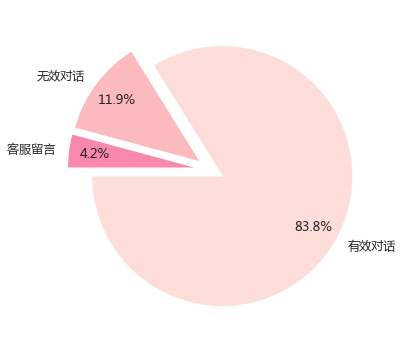

In [6]:
plt.figure(figsize=(8,6))
sizes = data['是否有效对话'].value_counts().values
labels = data['是否有效对话'].value_counts().index
plt.pie(sizes,labels = labels,autopct='%1.1f%%',startangle=180,explode = [0.1,0.1,00.1],pctdistance=0.8)
plt.show()

**各小组有效对话的占比**

In [7]:
ydf = data[data['是否有效对话']=='有效对话']

In [8]:
ydf['对话时长分组'] = pd.cut(ydf['对话时长-分'],bins = [0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,30,1430],
                      labels = ['1m','2m','3m','4m','5m','6m','7m','8m','9m','10m','11m','12m','13m','14m','15m','16m','17m','18m','19m','20m','30m','超30m'])

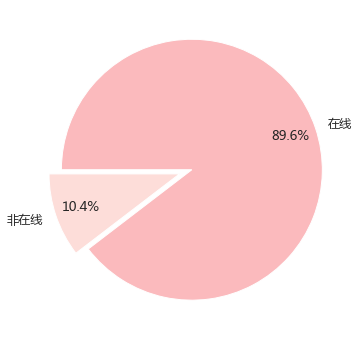

In [9]:
plt.figure(figsize=(8,6))
sizes = [10611,91454]
labels = ['非在线','在线']
plt.pie(sizes,labels = labels,autopct='%1.1f%%',startangle=180,explode = [0.1,0],pctdistance=0.8)
plt.show()

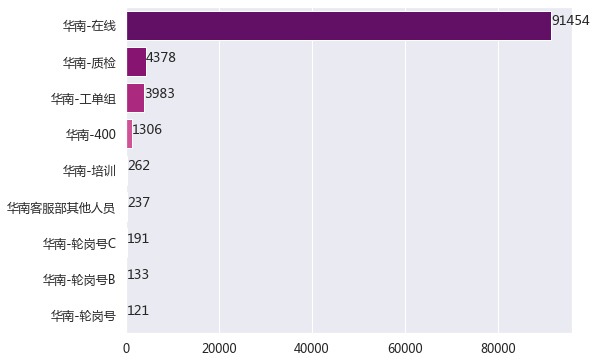

In [10]:
plt.figure(figsize=(8,6))
sns.countplot(y = '小类',data = ydf,order = ydf['小类'].value_counts().index,palette = 'RdPu_r')
# plt.xticks(rotation = 90)
plt.xlabel('')
plt.ylabel('')
con = list(ydf['小类'].value_counts().values)
for x,y in enumerate(con):
    plt.text(y+0.1,x,'%s' %y)
plt.show()

**选取华南-在线小组的数据分析对话时长问题**

In [11]:
zxdf = ydf[ydf['小类']=='华南-在线']

**工作日与周末的对话量对比**

In [12]:
workdf = zxdf[zxdf['是否工作日']=='workday']
weekendf = zxdf[zxdf['是否工作日'].isin(['Sunday','Saturday'])]

**工作日 VS 周末 各时段对话量——日均**

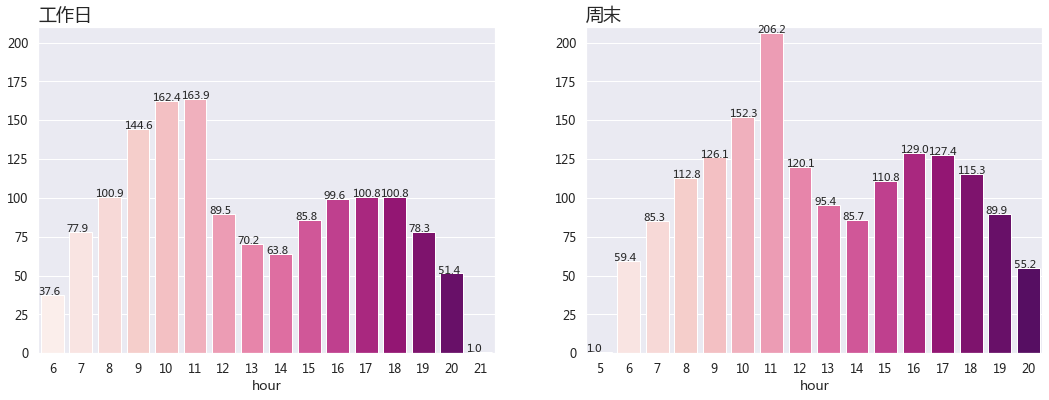

In [13]:
wm = workdf.groupby(['date','hour']).客服.count().reset_index(name='total')
wm = wm.groupby('hour').total.mean().round(1).reset_index(name = 'mean')

em = weekendf.groupby(['date','hour']).客服.count().reset_index(name='total')
em = em.groupby('hour').total.mean().round(1).reset_index(name = 'mean')

plt.figure(figsize = (18,6))
plt.subplot(1,2,1)
sns.barplot(x = 'hour',y = 'mean',palette = 'RdPu',data = wm)
plt.ylabel('')
plt.ylim(0,210)
con = list(wm['mean'])
for y,x in enumerate(con):
    plt.text(y-0.5,x,'%s' %x,size = 11)
    
plt.title('工作日',loc = 'left',fontsize = 18)


plt.subplot(1,2,2)
sns.barplot(x = 'hour',y = 'mean',palette = 'RdPu',data = em)
plt.ylabel('')
plt.ylim(0,210)
con = list(em['mean'])
for y,x in enumerate(con):
    plt.text(y-0.5,x,'%s' %x,size = 11)
    
plt.title('周末',loc = 'left',fontsize = 18)

plt.show()

* 可以很明显的发现4-5月的业务量各时段不平稳的情况在周末尤为明显，且周末下午时段高于工作日下午时段的日均量

* 另外11点时段仍处理高峰时段，但该时段恰好是早班午休，晚班未上班的时段，延申分析排队与掉线（排队时间过长放弃排队）、忙线是否也集中在该时段，若是，需重新规划班次时间

**帕累托图——各对话时长累计占比**

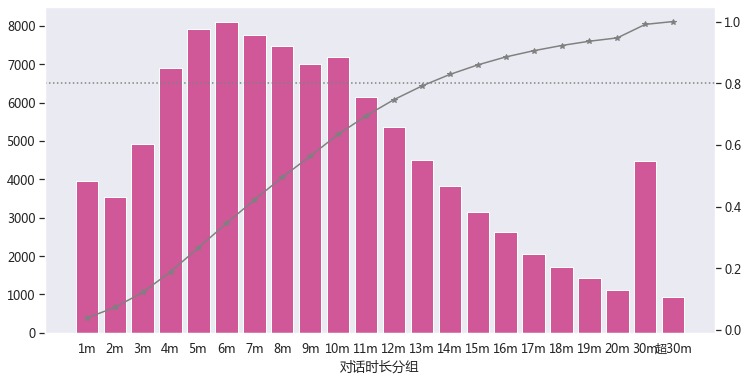

In [23]:
rlt = ydf.groupby('对话时长分组').对话时长分组.count().cumsum()/ydf.shape[0]
plt.figure(figsize = (12,6))
# sns.countplot(x = '对话时长分组',data = ydf,palette = 'RdPu_r')

plt.bar(ydf.groupby('对话时长分组').对话时长分组.count().index,ydf.groupby('对话时长分组').对话时长分组.count().values,color = '#D05798')

rlt.plot(color = 'gray',secondary_y = True,style = '-*')
plt.axhline(y = 0.8,ls=':',color = 'gray')
plt.grid(False)
plt.ylabel('')
plt.show()

63.4%的对话不超过10分钟，79.1%的对话时长不超过13分钟，超过20分钟的对话量占总对话量的 5.3% ，只有 0.09% 的对话量超 30 分钟

In [15]:
rlt.reset_index(name = '累计百分比')

,对话时长分组,累计百分比
0,1m,0.038642
1,2m,0.073198
2,3m,0.121501
3,4m,0.188997
4,5m,0.266477
5,6m,0.345760
6,7m,0.421770
7,8m,0.494939
8,9m,0.563562
9,10m,0.634027


In [16]:
result = zxdf[zxdf['对话时长-分']<30]
# print('对话时长分布')
# sns.jointplot(
#     data=result,
#     x="对话时长-分", y="hour",kind="kde"
# )
# plt.show()

**客户消息数与对话时长**

对话时长&客户消息数


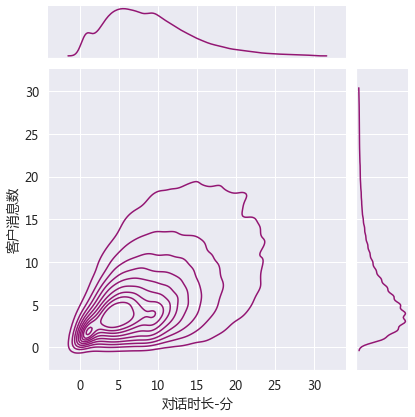

In [17]:
# sns.scatterplot(x='对话时长-分',y = '客户消息数',data = result)
result1 = result[result['客户消息数']<30]

print('对话时长&客户消息数')
sns.jointplot(
    data=result1,
    x="对话时长-分", y="客户消息数",kind="kde",color = '#931673',

)
plt.show()

**4-5月 整体对话时长分布**

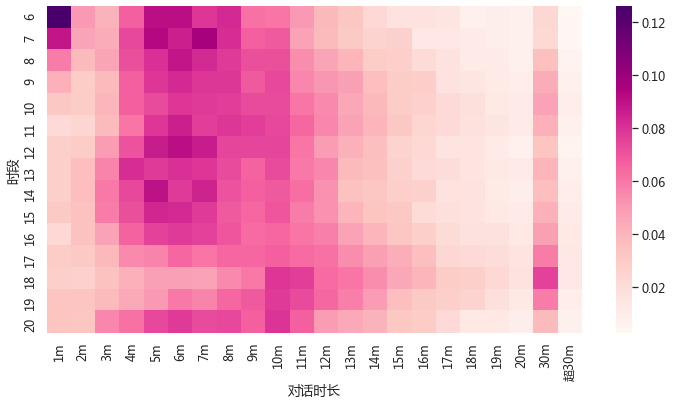

In [18]:
d1 = zxdf
# d1['hour']=d1['hour'].astype('str')
d1 = d1[(d1['hour']!=21)&(d1['hour']!=5)]

rd1 = d1.groupby(['对话时长分组','hour']).对话时长分组.count().reset_index(name = 'total')
rd1 = pd.pivot_table(rd1,index = 'hour',values = 'total',columns = '对话时长分组')

pd1 = rd1.div(rd1.sum(axis=1), axis=0).round(3)

plt.figure(figsize = (12,6))
sns.heatmap(pd1,cmap = 'RdPu')
plt.xlabel('对话时长')
plt.ylabel('时段')
plt.show()

剔除异常数据 ( 时长>30 m ，和客户消息数>30 ) 

对话时长主要集中在5-10分钟内，客户消息数主要集中在 1-7 之间

**在线组每人的对话时长**

**工作日 VS 周末 各时段对话时长分布情况**

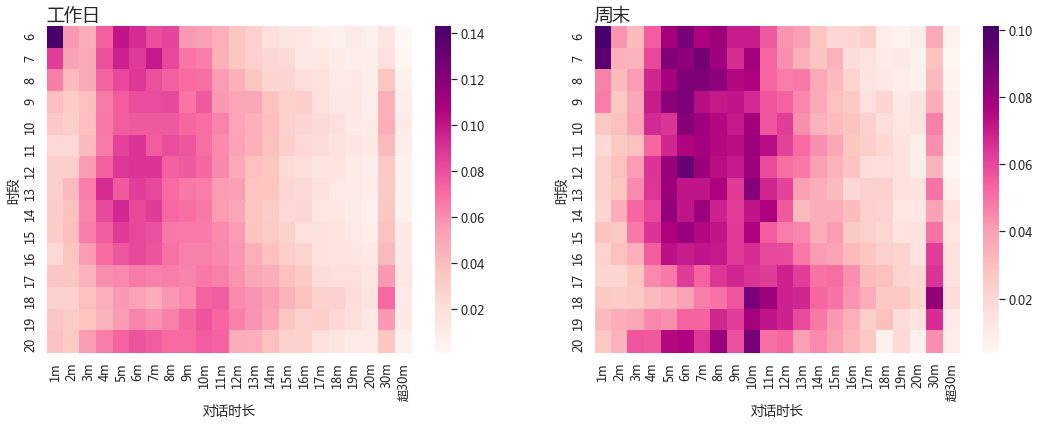

In [19]:
# 工作日
wk = workdf.groupby(['对话时长分组','hour']).对话时长分组.count().reset_index(name = 'total')
wk = pd.pivot_table(wk,index = 'hour',values = 'total',columns = '对话时长分组')
ctw = wk.div(wk.sum(axis=1), axis=0).round(3)

# 周末
we = weekendf.groupby(['对话时长分组','hour']).对话时长分组.count().reset_index(name = 'total')
we = pd.pivot_table(we,index = 'hour',values = 'total',columns = '对话时长分组')
cte = we.div(we.sum(axis= 1), axis=0).round(3)

# 可视化
plt.figure(figsize = (18,6))
# 工作日
ctw = ctw[ctw.index!=21]
plt.subplot(1,2,1)
sns.heatmap(ctw,cmap='RdPu')
plt.xlabel('对话时长')
plt.ylabel('时段')
plt.title('工作日',loc = 'left',fontsize = 18)

# 周末

cte = cte[(cte.index!=21)&(cte.index!=5)]
plt.subplot(1,2,2)
sns.heatmap(cte,cmap='RdPu')
plt.xlabel('对话时长')
plt.ylabel('时段')
plt.title('周末',loc = 'left',fontsize = 18)

plt.show()

* 1.不管是工作日还是周末，对话时长均集中在4-11或4-12分钟之间


* 2.对话时长超过30m的数据中，工作日集中16-20 点 这个时间段，周末集中在16-20 点 这个时间段 ，通常这个时间段会涉及到电商的问题，初步推测这些超长时间的对话大部分来自C端，由于该类超长时间对话不仅影响整体服务数据质量，且占线过长导致排队，响应不及时等等，进而做延申分析查找原因


**延申专题分析：**

*  验证超长时间的对话来自C端/B端的比例

*  集中在哪些问题上-升级客诉建工单的比例（对比历史与现分析阶段）

*  主要来自哪些省市

**对话时长超过30分钟的数据中哪些日期最多**

In [20]:
df_m30 = zxdf[zxdf['对话时长分组']=='超30m']

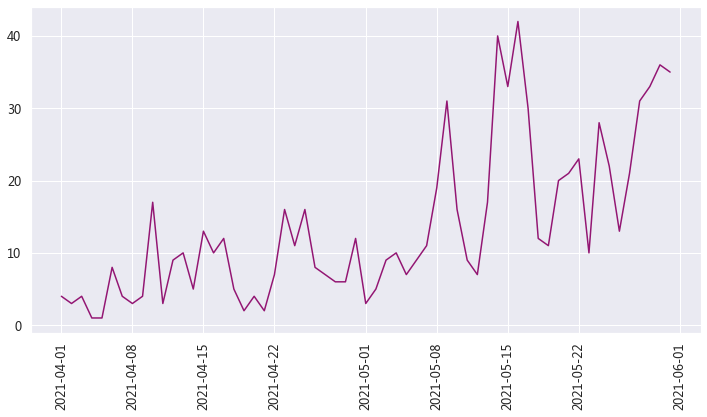

In [21]:
result_m30 = df_m30.groupby(['month','date']).客服.count().reset_index(name = 'total')
plt.figure(figsize = (12,6))
plt.plot('date','total',data = result_m30,color = '#931673')
# sns.lineplot(x = 'date',y='total',data = result_m30,color = '#931673')
plt.xticks(rotation = 90)
plt.show()

* 从上图可以看到4月份对话时长超30分钟对话量普遍在20条以下，但到5月份总体看对话时长超30分钟的对话量突然增加，结合小结工单验证以下问题：
* 1.疫情（不可抗力因素）的影响造成迟到的问题；
* 2.切仓出现的问题；
* 3.活动（5月促销活动的客诉问题-需结小结工单、运营优惠券派发核销、客诉量、客服补偿券进行验证分析）；
* 哪些问题客服没有办法解决，客户得不到满意的答复只能在线发泄情绪导致对话时间过长；

**上图对应的超30m的总数如下：**

In [22]:
result_m30

,month,date,total
0,4,2021-04-01,4
1,4,2021-04-02,3
2,4,2021-04-03,4
3,4,2021-04-04,1
4,4,2021-04-05,1
5,4,2021-04-06,8
6,4,2021-04-07,4
7,4,2021-04-08,3
8,4,2021-04-09,4
9,4,2021-04-10,17


**在线组每人的对话时长**